c:\Users\kmchw\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/11
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 2ms/step - accuracy: 0.7420 - loss: 1.0255 - val_accuracy: 0.9032 - val_loss: 0.3569
Epoch 2/11
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9007 - loss: 0.3565 - val_accuracy: 0.9189 - val_loss: 0.2908
Epoch 3/11
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9177 - loss: 0.2947 - val_accuracy: 0.9228 - val_loss: 0.2671
Epoch 4/11
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9258 - loss: 0.2687 - val_accuracy: 0.9329 - val_loss: 0.2393
Epoch 5/11
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9339 - loss: 0.2419 - val_accuracy: 0.9366 - val_loss: 0.2227
Epoch 6/11
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9372 - loss: 0.2267 - val_accuracy: 0.9407 - val_loss: 0.2087
Epoch 7/11
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.9424 - loss: 0.2104 - val_accuracy: 0.9436 - val_loss: 0.1953
Epoch 8/11
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.9423 - loss: 0.2039 - 

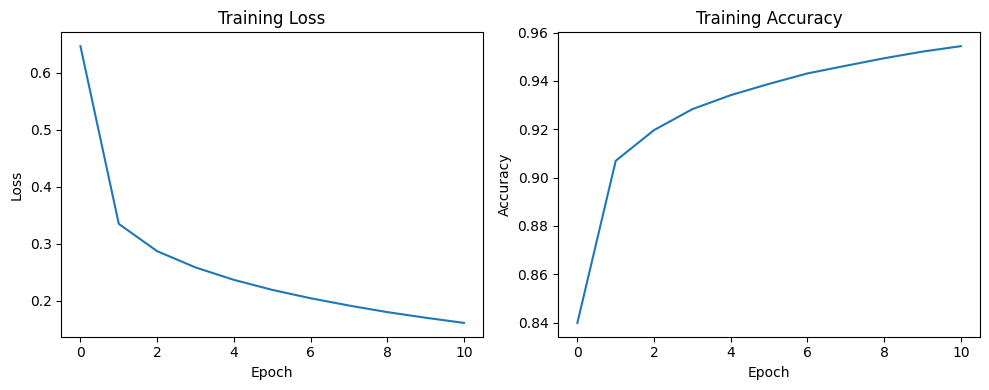

In [3]:
import tensorflow as tf
import matplotlib.pyplot as plt
import pandas as pd

# Load local MNIST dataset
train_data = pd.read_csv("Datasets/FNN_CNN/H_MNIST/mnist_train.csv")
test_data = pd.read_csv("Datasets/FNN_CNN/H_MNIST/mnist_test.csv")

# Separate labels and images
y_train = train_data.iloc[:, 0].values
x_train = train_data.iloc[:, 1:].values

y_test = test_data.iloc[:, 0].values
x_test = test_data.iloc[:, 1:].values

# Reshape images to 28x28
x_train = x_train.reshape(-1, 28, 28)
x_test = x_test.reshape(-1, 28, 28)

# Normalize pixel values to 0-1
x_train = x_train / 255.0
x_test = x_test / 255.0

# Define FNN architecture
model = tf.keras.Sequential([
    tf.keras.layers.Flatten(input_shape=(28, 28)),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax')
])

# Compile the model using SGD
model.compile(
    optimizer=tf.keras.optimizers.SGD(),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Train the model for 11 epochs
history = model.fit(
    x_train, y_train,
    epochs=11,
    validation_data=(x_test, y_test)
)

# Evaluate the model
loss, accuracy = model.evaluate(x_test, y_test)
print("Test Loss:", loss)
print("Test Accuracy:", accuracy)

# Plot training loss and accuracy
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['loss'])
plt.title('Training Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')

plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'])
plt.title('Training Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')

plt.tight_layout()
plt.show()

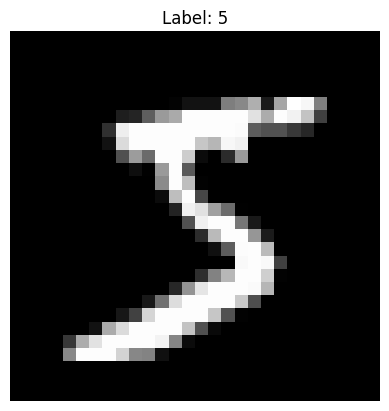

In [ ]:
import tensorflow as tf
import pandas as pd
import matplotlib.pyplot as plt

train_data = pd.read_csv("Datasets/FNN_CNN/H_MNIST/mnist_train.csv")
test_data = pd.read_csv("Datasets/FNN_CNN/H_MNIST/mnist_test.csv")

y_train = train_data.iloc[:, 0].values
x_train = train_data.iloc[:, 1:].values

y_test = test_data.iloc[:, 0].values
x_test = test_data.iloc[:, 1:].values

x_train = x_train.reshape(-1, 28, 28)
x_test = x_test.reshape(-1, 28, 28)

# plt.imshow(x_train[0], cmap='gray')
# plt.title("Label: " + str(y_train[0]))
# plt.axis('off')
# plt.show()

x_train = x_train / 255.0
x_test = x_test / 255.0

model = tf.keras.Sequential([
    tf.keras.layers.Flatten(input_shape=(28, 28)),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax')
])

model.compile(
    optimizer=tf.keras.optimizers.SGD(),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history = model.fit(
    x_train, y_train,
    epochs=11,
    validation_data=(x_test, y_test)
)

loss, accuracy = model.evaluate(x_test, y_test)
print("Test Loss:", loss)
print("Test Accuracy:", accuracy)

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['loss'])
plt.title('Training Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')

plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'])
plt.title('Training Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')

plt.show()